<a href="https://colab.research.google.com/github/bibekgurau/CN5006/blob/main/week2LabLinearRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:

import shap
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# 1. Load the online food delivery dataset
df = pd.read_csv("online food delivery dataset-selected-columns.csv")

# 2. Remove rows with missing values
df = df.dropna().copy()

# 3. Select the target variable
# Predict customer Age
target = "Age"

X = df.drop(columns=[target])
y = df[target]

# 4. Identify numerical and categorical features
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# 5. Preprocess categorical features using One-Hot Encoding
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# 6. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

Mean Squared Error: 4.51
R² Score: 0.39


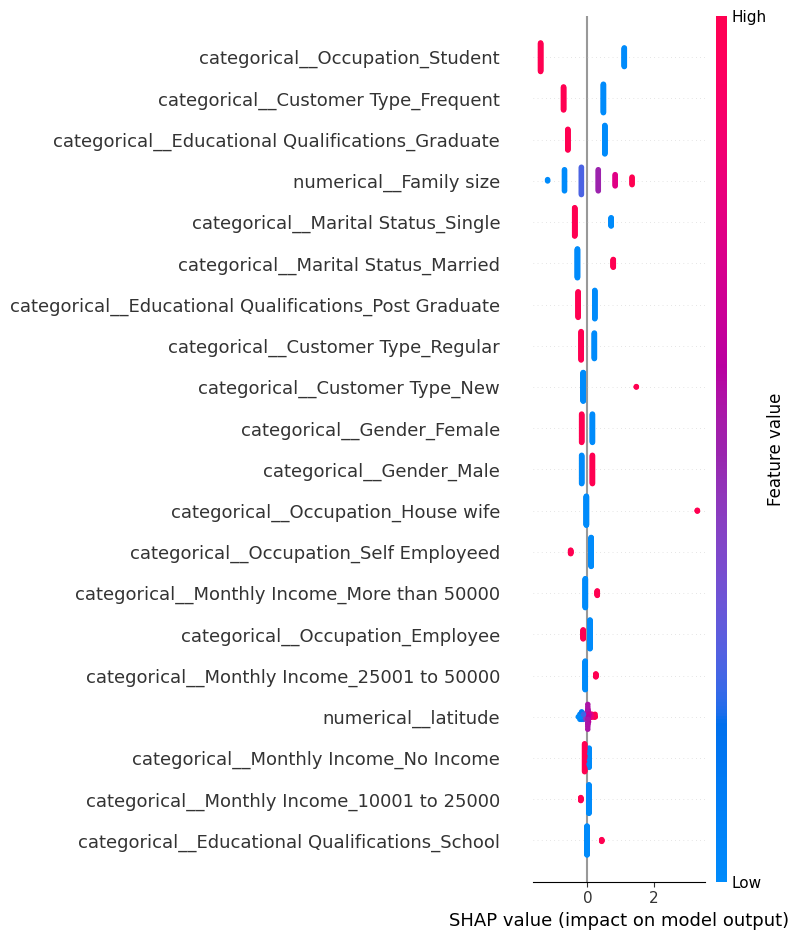

In [8]:
# 7. Create and train the Linear Regression pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

# 8. Predict and evaluate the model
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.2f}")

# 9. Transform the data for SHAP
X_train_transformed = model.named_steps[
    "preprocessor"
].transform(X_train)

X_test_transformed = model.named_steps[
    "preprocessor"
].transform(X_test)

feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Convert transformed data to DataFrames
X_train_transformed = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_train.index
)

X_test_transformed = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

# 10. Create SHAP explainer
regression_model = model.named_steps["regressor"]

explainer = shap.LinearExplainer(
    regression_model,
    X_train_transformed
)

shap_values = explainer(X_test_transformed)

# 11. Generate SHAP summary plot
shap.summary_plot(
    shap_values,
    X_test_transformed,
    show=False
)

plt.tight_layout()
plt.savefig("shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


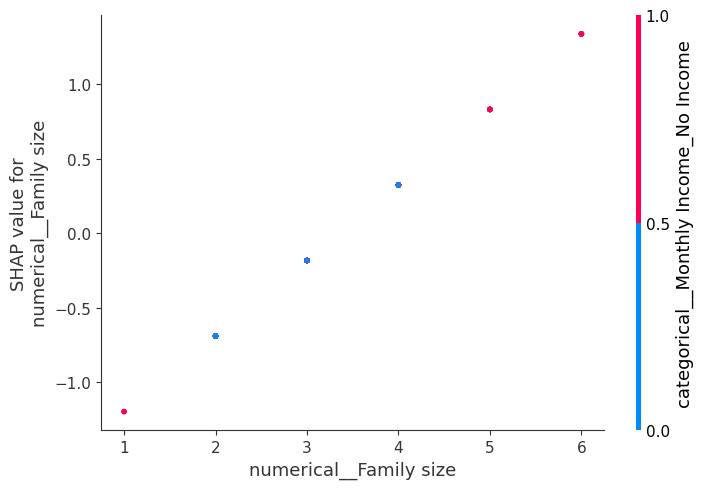

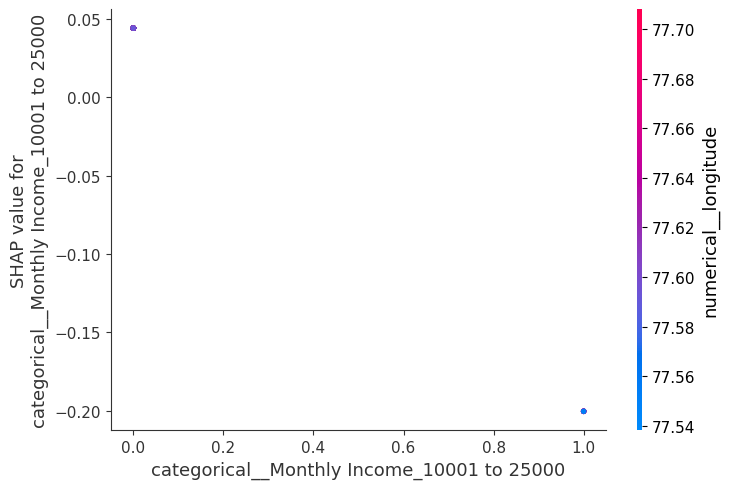

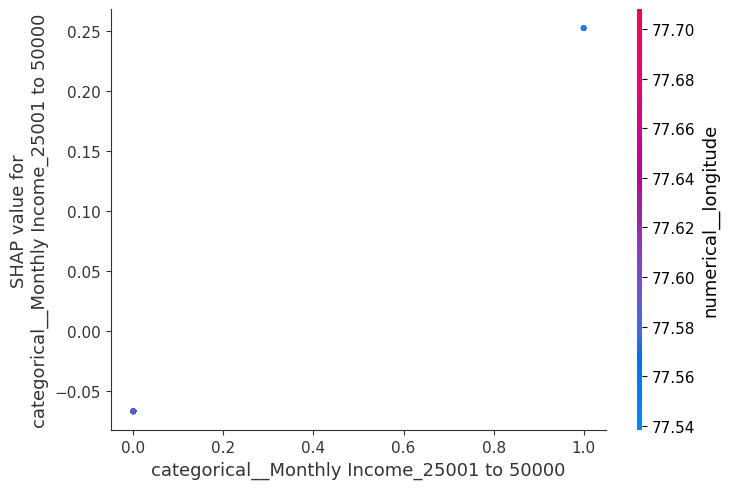

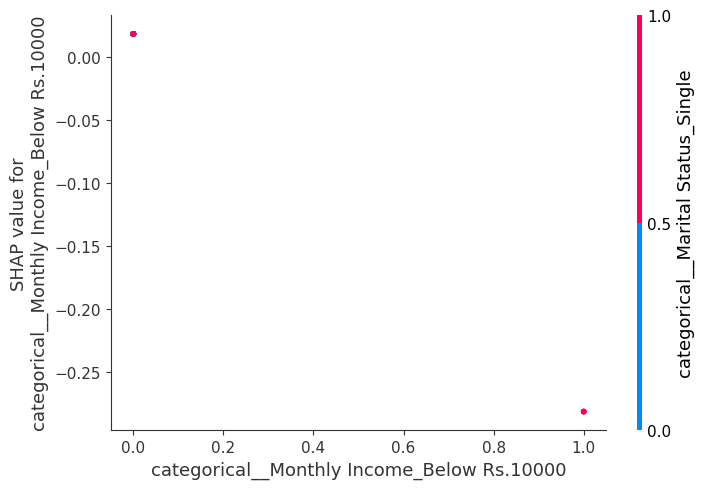

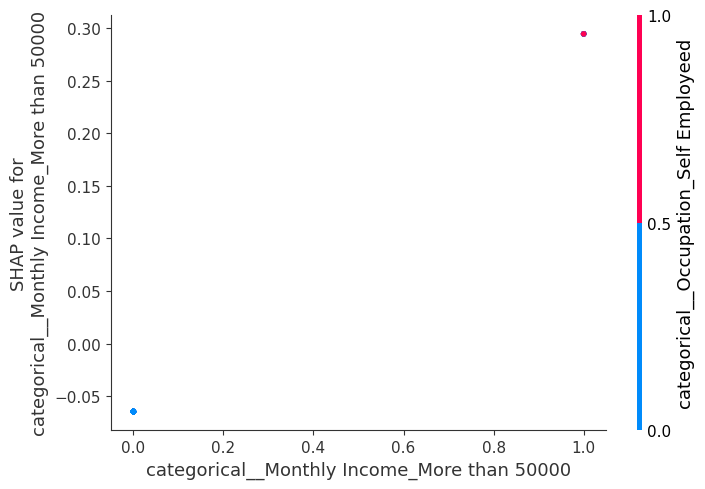

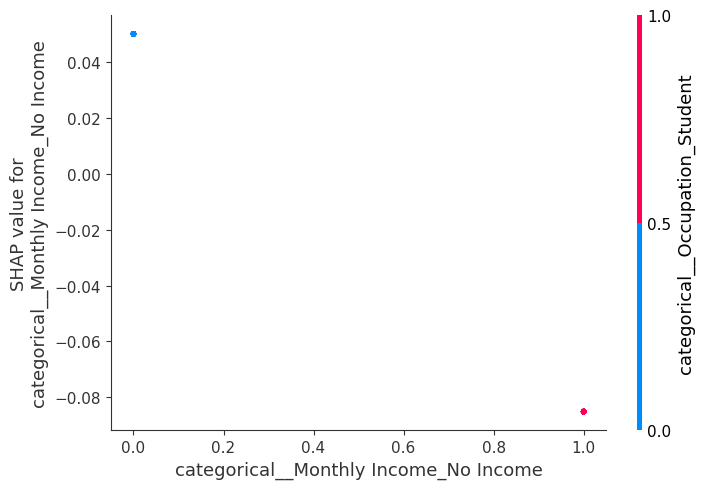

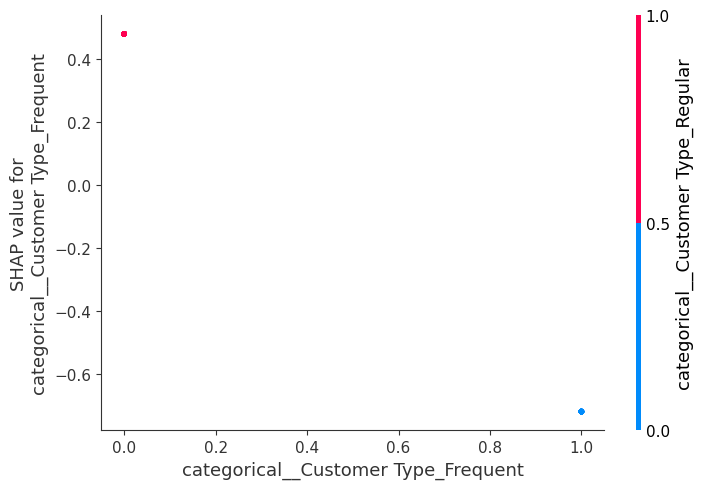

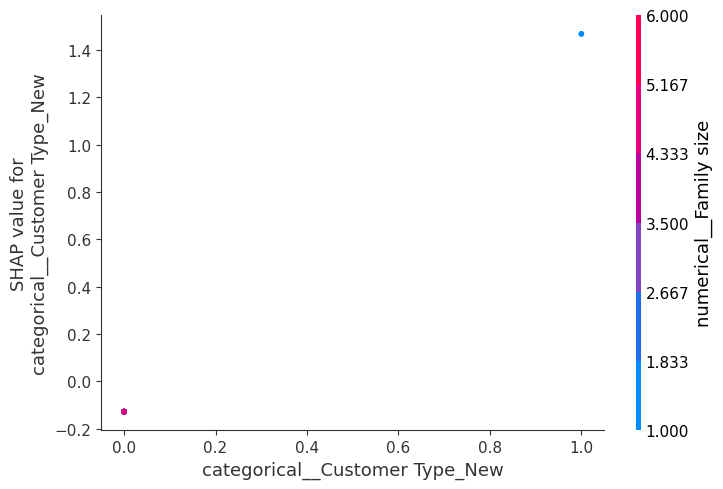

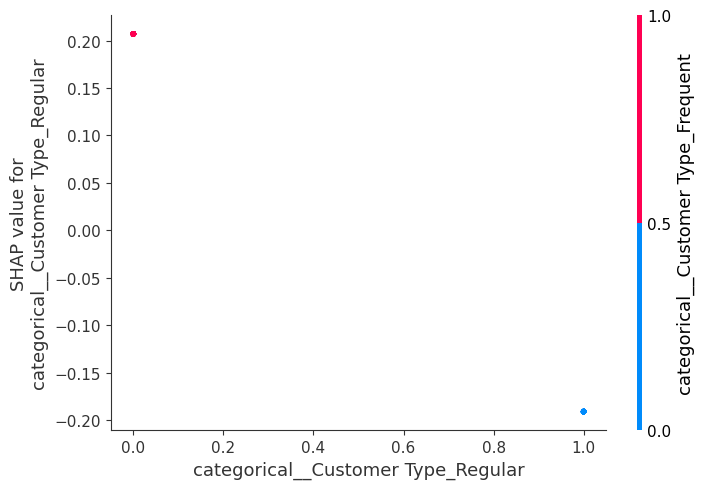

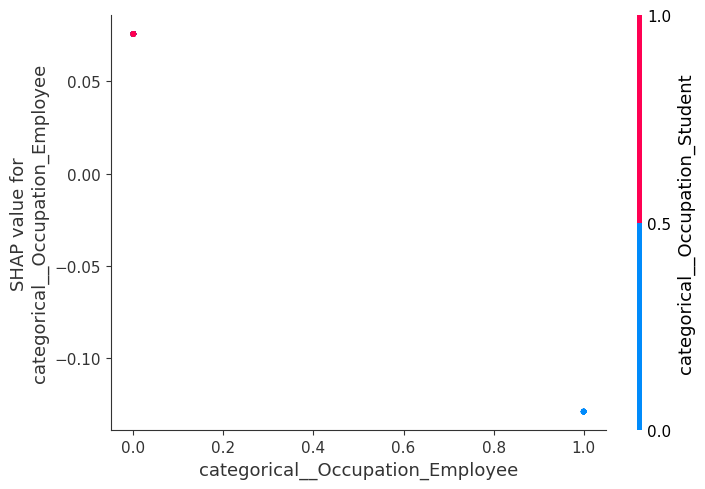

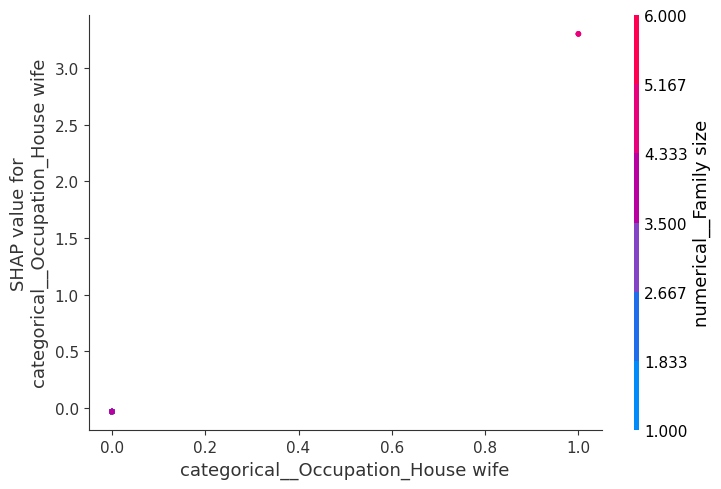

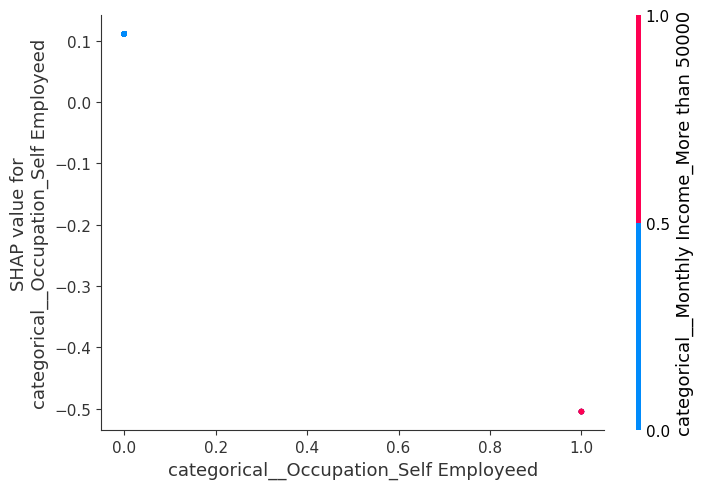

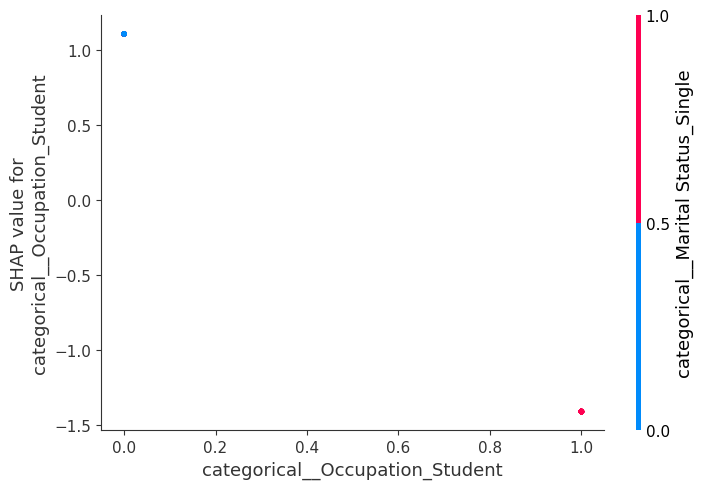

SHAP plots saved successfully.


In [9]:
# 12. Generate SHAP dependence plots
# Select available features after encoding
selected_features = [
    feature for feature in [
        "Age",
        "Family size",
        "Monthly Income",
        "Customer Type",
        "Occupation"
    ]
    if feature in X.columns
]

for feature in selected_features:
    # Find the corresponding encoded column(s)
    matching_features = [
        col for col in feature_names
        if col == f"numerical__{feature}"
        or col.startswith(f"categorical__{feature}_")
    ]

    for encoded_feature in matching_features:
        shap.dependence_plot(
            encoded_feature,
            shap_values.values,
            X_test_transformed,
            feature_names=feature_names,
            show=False
        )

        safe_name = (
            encoded_feature.replace("/", "_")
            .replace(" ", "_")
            .replace("=", "_")
        )

        plt.tight_layout()
        plt.savefig(
            f"shap_dependence_{safe_name}.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close()

print("SHAP plots saved successfully.")